# Практическая работа №2

## Разведочный анализ данных (EDA)

**Вариант B**

**Датасет:** Palmer Penguins

**Цель работы:** провести разведочный анализ данных, определить типы признаков, найти пропуски и выбросы, исследовать распределения, корреляции и баланс целевой переменной.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/penguins.csv")

display(df.head())

print("Размер таблицы:", df.shape)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Размер таблицы: (344, 7)


In [3]:
print("Информация о данных:")
df.info()

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nЧисловая статистика:")
display(df.describe())

print("\nКатегориальная статистика:")
cat_cols = df.select_dtypes(include=["object", "string", "category"]).columns
display(df[cat_cols].describe())

Информация о данных:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB

Пропущенные значения:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Числовая статистика:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000



Категориальная статистика:


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,MALE
freq,152,168,168


### Общий осмотр данных

Датасет содержит 344 записи и 7 признаков.

Числовые признаки описывают физические характеристики пингвинов, а категориальные — вид, остров и пол.

Обнаружены пропущенные значения, особенно в столбце sex. Они потребуют обработки перед обучением модели.

Также необходимо проверить распределение числовых признаков, возможные выбросы и связи между характеристиками.

### Классификация признаков

| Признак | Тип | Описание |
|---|---|---|
| species | Категориальный | Вид пингвина, целевая переменная |
| island | Категориальный | Остров обитания |
| bill_length_mm | Числовой | Длина клюва |
| bill_depth_mm | Числовой | Глубина клюва |
| flipper_length_mm | Числовой | Длина ласты |
| body_mass_g | Числовой | Масса тела |
| sex | Категориальный | Пол пингвина |

Целевая переменная species содержит три класса: Adelie, Chinstrap и Gentoo. Следовательно, это задача многоклассовой классификации.

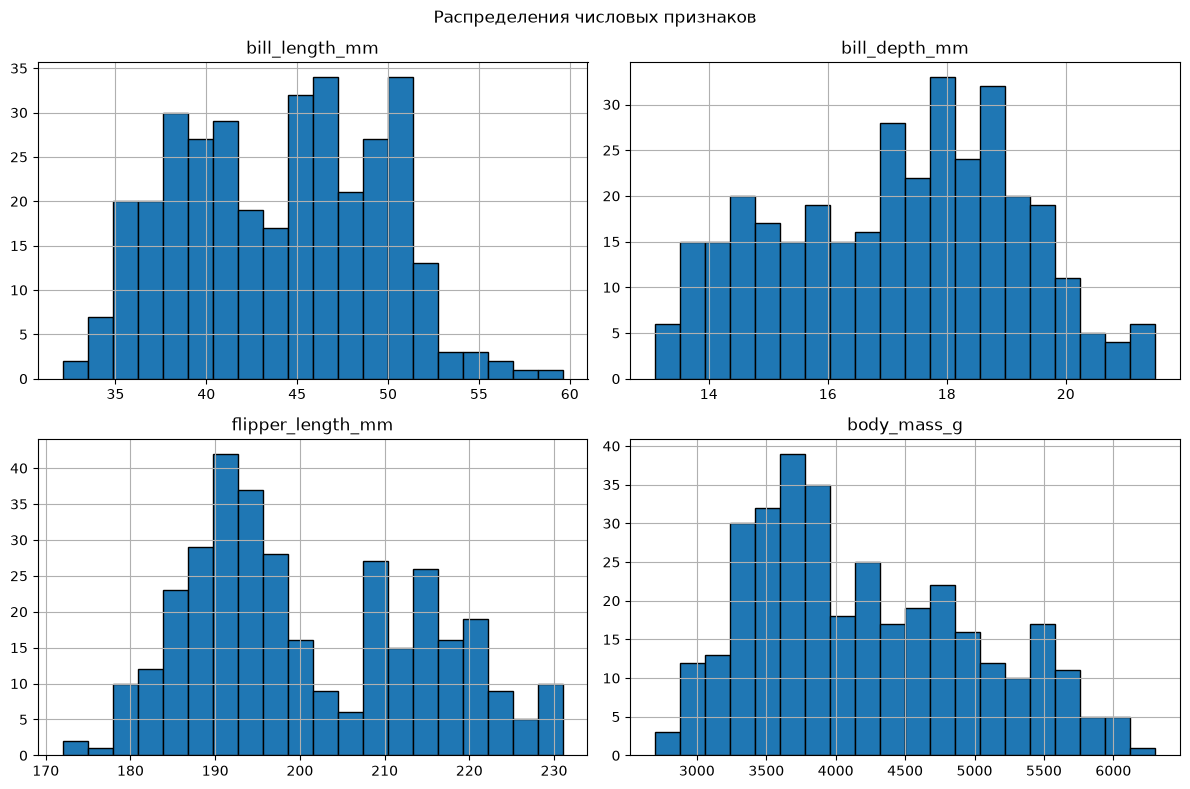

In [4]:
numeric_cols = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

df[numeric_cols].hist(
    bins=20,
    figsize=(12, 8),
    edgecolor="black"
)

plt.suptitle("Распределения числовых признаков")
plt.tight_layout()
plt.show()

### Анализ распределений

Масса тела и размеры пингвинов имеют неоднородные распределения.

На некоторых гистограммах заметны несколько выраженных групп значений. Это может быть связано с различиями между видами пингвинов.

Для более подробного анализа необходимо проверить распределения отдельно по видам.

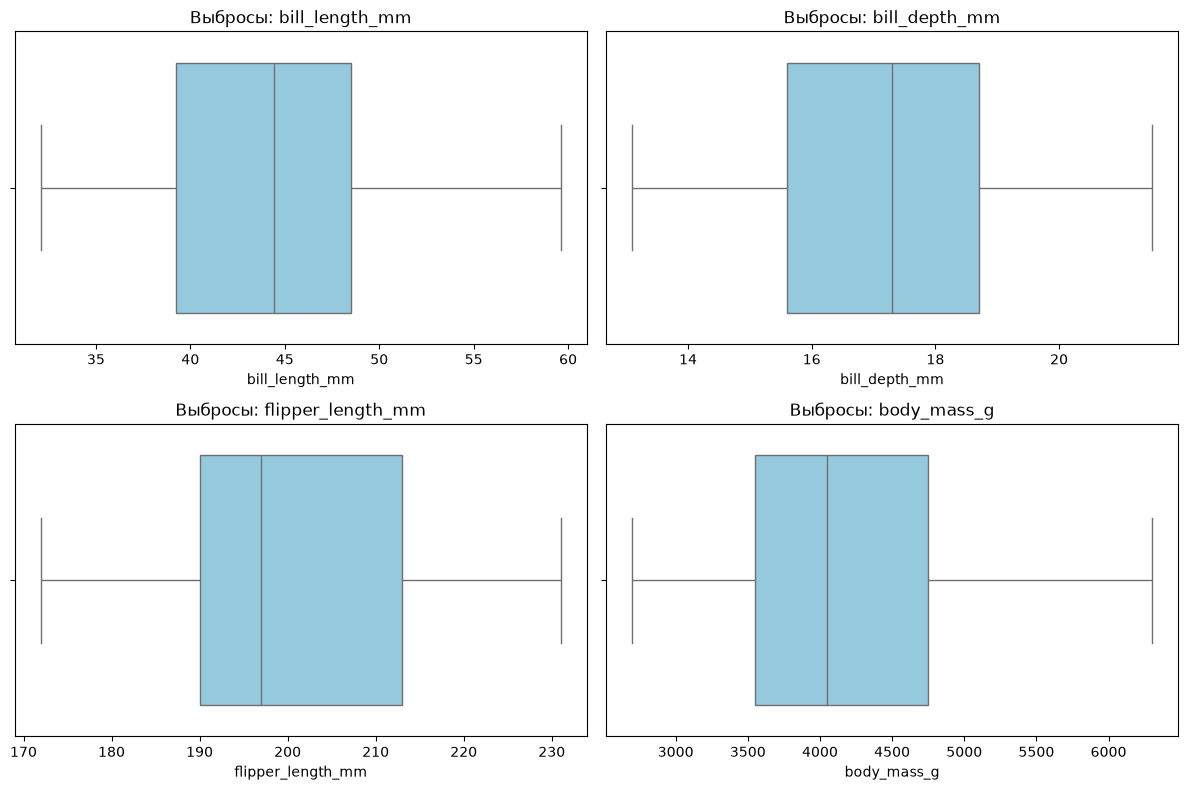

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(
        data=df,
        x=col,
        ax=ax,
        color="skyblue"
    )

    ax.set_title(f"Выбросы: {col}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

In [6]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f"{col}: {len(outliers)} потенциальных выбросов")

bill_length_mm: 0 потенциальных выбросов
bill_depth_mm: 0 потенциальных выбросов
flipper_length_mm: 0 потенциальных выбросов
body_mass_g: 0 потенциальных выбросов


### Анализ выбросов

Потенциальные выбросы проверены с помощью boxplot и межквартильного размаха (IQR).

Значения за пределами Q1 − 1,5 × IQR и Q3 + 1,5 × IQR считаются потенциальными выбросами.

Такие значения не следует сразу удалять, поскольку они могут отражать реальные различия между видами пингвинов.

In [7]:
categorical_cols = ["species", "island", "sex"]

for col in categorical_cols:
    print(f"\nПризнак: {col}")
    print(df[col].value_counts(dropna=False))


Признак: species
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Признак: island
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

Признак: sex
sex
MALE      168
FEMALE    165
NaN        11
Name: count, dtype: int64


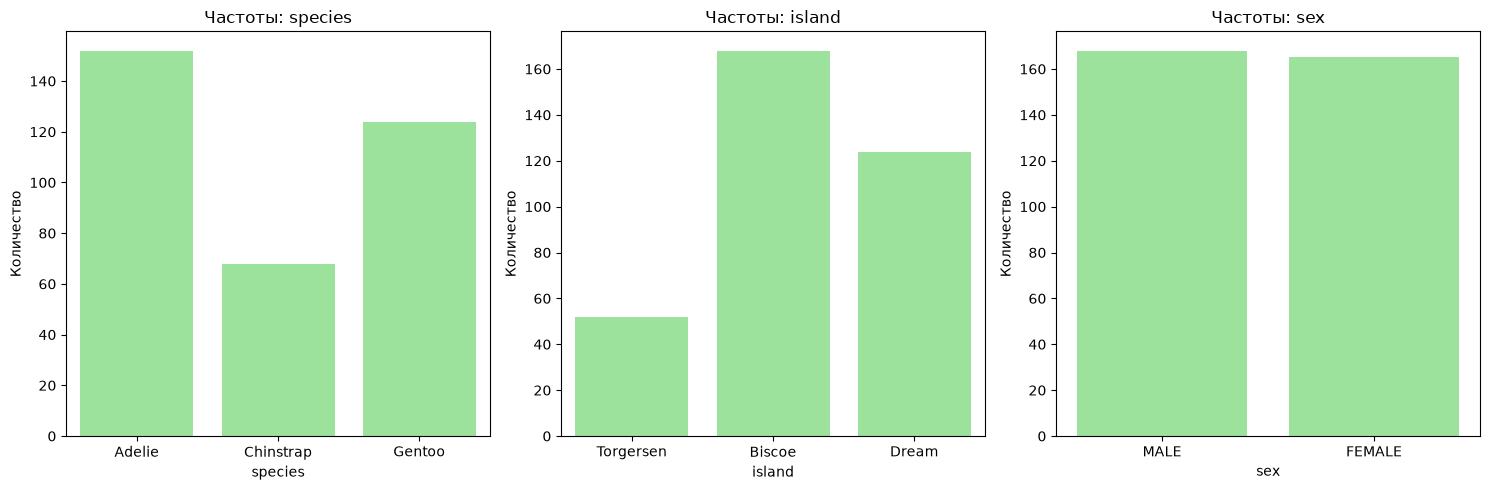

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, categorical_cols):
    sns.countplot(
        data=df,
        x=col,
        ax=ax,
        color="lightgreen"
    )

    ax.set_title(f"Частоты: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Количество")

plt.tight_layout()
plt.show()

In [9]:
for col in categorical_cols:
    counts = df[col].value_counts(dropna=False)

    rare = counts[counts < 10]

    print(f"\nРедкие категории в {col}:")

    if rare.empty:
        print("Нет категорий с частотой менее 10")
    else:
        print(rare)


Редкие категории в species:
Нет категорий с частотой менее 10

Редкие категории в island:
Нет категорий с частотой менее 10

Редкие категории в sex:
Нет категорий с частотой менее 10


### Анализ категориальных признаков

В датасете представлены три вида пингвинов и три острова.

Наиболее многочисленным видом является Adelie, а наименее многочисленным — Chinstrap.

Распределение видов и островов неравномерное. В признаке sex присутствуют пропущенные значения.

При дальнейшей предобработке необходимо обработать пропуски и закодировать категориальные признаки.

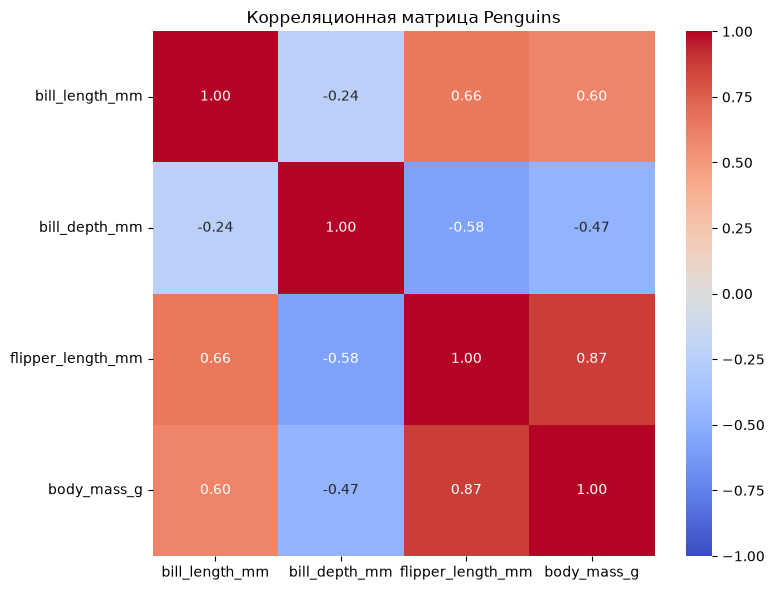

In [10]:
corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица Penguins")
plt.tight_layout()
plt.show()

### Анализ корреляций

Корреляционная матрица показывает линейные связи между числовыми признаками.

Между длиной ласты и массой тела наблюдается сильная положительная корреляция: более крупные ласты часто встречаются у более тяжёлых пингвинов.

Корреляция не доказывает причинно-следственную связь. На результаты также могут влиять различия между видами.

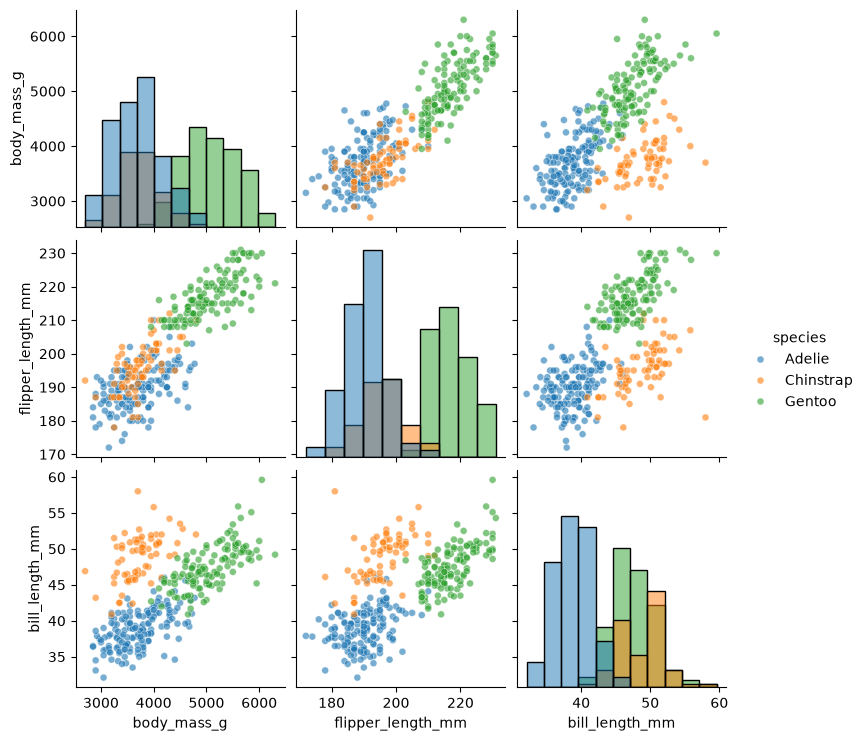

In [11]:
sns.pairplot(
    df,
    vars=[
        "body_mass_g",
        "flipper_length_mm",
        "bill_length_mm"
    ],
    hue="species",
    diag_kind="hist",
    plot_kws={
        "alpha": 0.6,
        "s": 25
    }
)

plt.show()

### Анализ диаграмм рассеяния

На диаграммах видно, что виды пингвинов частично образуют отдельные группы по физическим характеристикам.

Особенно заметны различия Gentoo по массе тела и длине ласты.

При этом некоторые значения разных видов пересекаются, поэтому для точной классификации желательно использовать несколько признаков одновременно.

Количество по классам:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Проценты по классам:
species
Adelie       44.19
Gentoo       36.05
Chinstrap    19.77
Name: proportion, dtype: float64


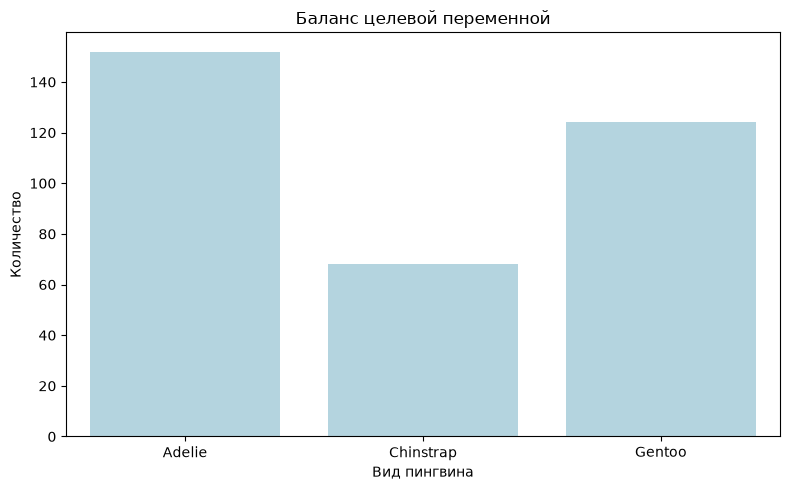

In [12]:
print("Количество по классам:")
print(df["species"].value_counts())

print("\nПроценты по классам:")
print(
    (df["species"].value_counts(normalize=True) * 100)
    .round(2)
)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species",
    order=["Adelie", "Chinstrap", "Gentoo"],
    color="lightblue"
)

plt.title("Баланс целевой переменной")
plt.xlabel("Вид пингвина")
plt.ylabel("Количество")

plt.tight_layout()
plt.show()

### Анализ дисбаланса классов

В данных больше всего пингвинов Adelie (44,2%), затем Gentoo (36,0%) и Chinstrap (19,8%).

Присутствует умеренная неравномерность классов. При последующем обучении классификатора рекомендуется использовать стратифицированное разделение данных и оценивать качество не только по Accuracy, но и по Macro F1.

## Итоговый отчёт EDA

1. **Пропущенные значения.** В признаках bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g и sex обнаружены пропуски. Для числовых признаков планируется использовать медиану, для категориального sex — отдельную категорию Unknown.

2. **Потенциальные выбросы.** Числовые характеристики проверены методом IQR. Крайние значения необходимо исследовать перед удалением, поскольку они могут быть настоящими особенностями отдельных видов.

3. **Различия между видами.** Gentoo обычно имеют большую массу тела и более длинные ласты. Эти признаки могут быть полезными при классификации.

4. **Корреляция признаков.** Между массой тела и длиной ласты обнаружена сильная положительная связь. При построении моделей необходимо учитывать коррелирующие признаки.

5. **Категориальные данные.** Признаки island и sex требуют кодирования в числовой формат, например с помощью OneHotEncoder.

6. **Дисбаланс классов.** Вид Chinstrap представлен реже остальных. Для корректной оценки классификатора нужно использовать стратификацию и метрики, учитывающие качество по всем классам.

7. **Предотвращение утечки данных.** Заполнение пропусков, масштабирование и кодирование признаков следует обучать только на тренировочной выборке, а затем применять к тестовой.

### План следующей практической

В практической №3 будет создан Pipeline с SimpleImputer, StandardScaler и OneHotEncoder, объединёнными через ColumnTransformer.

Данные сначала разделим на train и test, чтобы предотвратить утечку информации.